# Module 2: Data
### BWSI SGAI 2026

By the end of this module you'll know:
- Where humanoid images and labels come from
- How the CSV columns map to the four game states
- What `Item` and `Gender` are — and why they're the easiest extension point
- How to explore the dataset with pandas

---
*Open this notebook in JupyterLab. Press `Alt+R` to enter slideshow mode.*  
*Students: just scroll through normally and run the exercise cells.*

## Where does the game get humanoids?

Each turn, the game needs a Humanoid object — someone to decide about.

That Humanoid comes from the `data/` directory:

- **One CSV file** — `consolidated_metadata.csv` — one row per humanoid, with labels
- **200 PNG images** — one per humanoid, in `consolidated_dataset/`

The game reads a row from the CSV, builds a `Humanoid` object, loads the image for display, and hands it to you.

> No ML here yet. This is just the raw material — the ground truth the CNN is trying to predict.

## Where does this live in the code?

```
bwsi-sgai/
├── data/                              ← this module
│   ├── consolidated_metadata.csv      ← now
│   └── consolidated_dataset/          ← 200 PNG images
├── gameplay/
├── game_interfaces/
├── models/
├── ui/
├── training/
└── tests/
```

*`data/` is read-only at runtime — the game reads from it, nothing writes to it.*  
*`game_interfaces/data_parser.py` is what does the reading (covered in Module 4).*

*`bwsi-sgai/data/consolidated_metadata.csv`*

## The CSV — Locate

```
bwsi-sgai/
├── data/
│   ├── consolidated_metadata.csv    ← here
│   └── consolidated_dataset/
```

Open `data/consolidated_metadata.csv` in JupyterLab (double-click → CSV viewer) or a spreadsheet.

**What you'll see:** 200 rows, one per humanoid. Five columns.

*`bwsi-sgai/data/consolidated_metadata.csv`*

## The CSV — Orient

The header and first few rows look like this:

| Class | Injured | Gender | Item | Filename |
|-------|---------|--------|------|----------|
| Default | False | Female | Bow | consolidated_dataset/test_00000.png |
| Default | False | Female | Hammer | consolidated_dataset/test_00001.png |
| Default | False | Female | Bow | consolidated_dataset/test_00002.png |
| Default | False | Male | NaN | consolidated_dataset/test_00003.png |
| Zombie | True | Female | NaN | consolidated_dataset/test_00004.png |

| Column | Values | What it means |
|--------|--------|---------------|
| `Class` | `"Default"` or `"Zombie"` | `"Default"` = human; anything else = zombie |
| `Injured` | `True` / `False` | Whether the humanoid is injured |
| `Gender` | `"Male"` / `"Female"` | Humanoid's apparent gender |
| `Item` | `"Bow"`, `"Hammer"`, `"Staff"`, or `NaN` | Item being carried (97 rows have none) |
| `Filename` | `consolidated_dataset/test_NNNNN.png` | Relative path to the image |

*`bwsi-sgai/data/consolidated_metadata.csv`*

## The CSV — Touch

Run the cell below. You're loading the dataset the same way `DataParser` does — no special imports needed, just pandas.

In [1]:
import os
import sys
from pathlib import Path
%matplotlib inline

# Ensure the project root is the working directory and is on sys.path,
# so local packages (game_interfaces, gameplay, models) are importable
# and relative paths like DATA_DIR="data" resolve correctly.
# Works whether Jupyter was launched from bwsi-sgai/ or lectures/.
_here = Path().resolve()
_root = _here.parent if _here.name == "lectures" else _here
os.chdir(_root)
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

In [2]:
import pandas as pd

df = pd.read_csv("data/consolidated_metadata.csv")

print(f"Shape: {df.shape}  ({df.shape[0]} rows × {df.shape[1]} columns)")
print()
df.head(6)

Shape: (200, 5)  (200 rows × 5 columns)



,Class,Injured,Gender,Item,Filename
0,Default,False,Female,Bow,consolidated_dataset/test_00000.png
1,Default,False,Female,Hammer,consolidated_dataset/test_00001.png
2,Default,False,Female,Bow,consolidated_dataset/test_00002.png
3,Default,False,Male,NaN,consolidated_dataset/test_00003.png
4,Zombie,True,Female,NaN,consolidated_dataset/test_00004.png
5,Zombie,True,Female,Bow,consolidated_dataset/test_00005.png


> `Filename` is a **relative path** — relative to the repo root.  
> That's why JupyterLab must be launched from `bwsi-sgai/`, not from inside `data/`.  
> If you get a `FileNotFoundError` for images later, this is the most likely cause.

## Now: how the CSV becomes a game state

```
bwsi-sgai/
├── data/
│   ├── consolidated_metadata.csv
│   └── consolidated_dataset/
├── game_interfaces/
│   └── data_parser.py          ← where this mapping lives
├── gameplay/
│   └── enums.py                ← where State is defined
├── models/
├── ui/
├── training/
└── tests/
```

*`DataParser` reads each CSV row and decides which of the four states applies.*  
*The CNN tries to guess what the CSV already knows.*

*`bwsi-sgai/game_interfaces/data_parser.py`*

## How State Is Assigned

Two columns — `Class` and `Injured` — combine to produce one of four game states:

| Class | Injured | State |
|-------|---------|-------|
| `"Default"` | `False` | **healthy** |
| `"Default"` | `True` | **injured** |
| anything else | `False` | **zombie** |
| anything else | `True` | **corpse** |

This mapping lives in `datarow_to_state()` in `game_interfaces/data_parser.py` (line 103).  
To add a new state (say, `"mutant"`), you'd edit that function **and** add the value to `gameplay/enums.py`.

> **Ground truth vs. CNN:** The CSV has the real answer. The CNN is making a guess.  
> If they disagree, the CSV is right.

*`bwsi-sgai/data/consolidated_metadata.csv`*

## State Breakdown — Touch

Run the cell below. You're computing the per-state counts from the CSV using the same logic `DataParser` uses.

In [3]:
import pandas as pd

df = pd.read_csv("data/consolidated_metadata.csv")

# Apply the same logic as datarow_to_state() in data_parser.py
def assign_state(row):
    is_human = row["Class"] == "Default"
    if is_human and not row["Injured"]:
        return "healthy"
    elif is_human and row["Injured"]:
        return "injured"
    elif not is_human and not row["Injured"]:
        return "zombie"
    else:
        return "corpse"

df["State"] = df.apply(assign_state, axis=1)

counts = df["State"].value_counts()
print("State breakdown (200 total):")
print()
for state, count in sorted(counts.items()):
    print(f"  {state:<10} {count:>3}  {'█' * count}")

State breakdown (200 total):

  corpse      44  ████████████████████████████████████████████
  healthy     81  █████████████████████████████████████████████████████████████████████████████████
  injured     29  █████████████████████████████
  zombie      46  ██████████████████████████████████████████████


> **Expected output:** healthy=81, zombie=46, corpse=44, injured=29  
> The dataset is unbalanced — healthy images outnumber injured nearly 3:1.  
> This matters for CNN training: a naive model that always predicts "healthy" would be right 40% of the time.

INSTRUCTOR NOTES:
Ask students: why does class imbalance matter for training a CNN?
The injured class has only 29 examples — this is why the CNN struggles most with injured vs. healthy.
Point out that zombie and corpse are also underrepresented relative to healthy.
The OracleClassifier (Module 5) sidesteps this entirely by just reading the CSV directly.

## Now: the images

```
bwsi-sgai/
├── data/
│   ├── consolidated_metadata.csv
│   └── consolidated_dataset/     ← now
│       ├── test_00000.png        (healthy)
│       ├── test_00001.png
│       ├── ...
│       └── test_00199.png
├── gameplay/
├── models/
├── ui/
└── training/
```

*200 PNG files. Filenames match the `Filename` column in the CSV.*

*`bwsi-sgai/data/consolidated_dataset/`*

## The Images — Orient

Each image:
- **Format:** PNG
- **Naming:** `test_NNNNN.png` where `NNNNN` is a zero-padded integer
- **Content:** a rendered humanoid figure on a plain background
- **Linked to CSV:** via the `Filename` column — `consolidated_dataset/test_00000.png`

The game loads images using `PIL` (Pillow) in `game_interfaces/data_parser.py`.  
The CNN is trained on these exact images — it learns to recognize visual features that distinguish the four states.

Run the cell below to see one image per state.

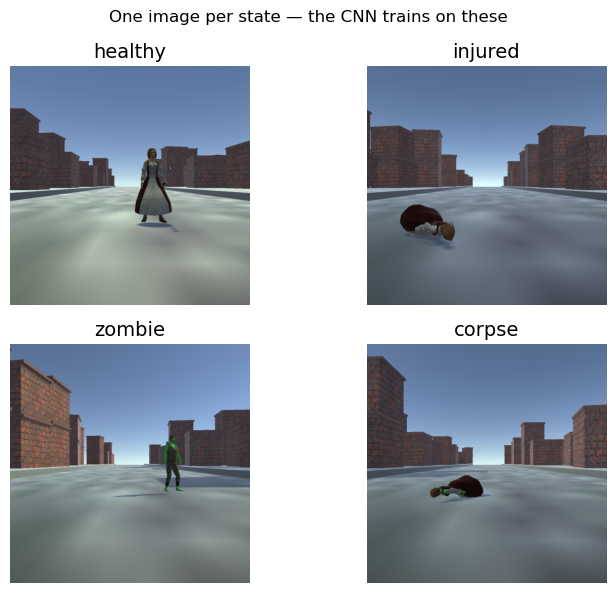

In [4]:
from PIL import Image
import matplotlib.pyplot as plt

# One representative image per state (from consolidated_metadata.csv)
examples = [
    ("healthy",  "data/consolidated_dataset/test_00000.png"),
    ("injured",  "data/consolidated_dataset/test_00006.png"),
    ("zombie",   "data/consolidated_dataset/test_00007.png"),
    ("corpse",   "data/consolidated_dataset/test_00004.png"),
]

fig, axes = plt.subplots(2, 2, figsize=(8, 6))
for ax, (state, fname) in zip(axes.flat, examples):
    img = Image.open(fname)
    ax.imshow(img)
    ax.set_title(state, fontsize=14)
    ax.axis("off")

plt.suptitle("One image per state — the CNN trains on these", fontsize=12)
plt.tight_layout()
plt.show()

> **What visual features distinguish them?**  
> Healthy vs. injured: posture, limb position, visible bandaging.  
> Zombie vs. corpse: the same — zombies walk, corpses lie still.  
> The CNN learns these distinctions from the training images. The CSV labels tell it what the correct answer is.

## Now: the extra columns

```
bwsi-sgai/
├── data/
│   └── consolidated_metadata.csv
│       Columns: Class · Injured · Gender · Item · Filename
│                                   ↑          ↑
│                               unused by default — extension points
├── game_interfaces/
│   └── data_parser.py     ← datarow_to_value() is where you'd use them
└── ...
```

*`Item` and `Gender` are in every row. Nothing reads them in the default game.  
They're waiting for you.*

*`bwsi-sgai/game_interfaces/data_parser.py`*

## Item and Gender — Orient

**`Item`** — what the humanoid is carrying:
- Values: `"Bow"`, `"Hammer"`, `"Staff"`, or `NaN` (97 of 200 humanoids carry nothing)
- Unused by default

**`Gender`** — apparent gender:
- Values: `"Male"` (105), `"Female"` (95)
- Unused by default

**Where to use them:**  
`datarow_to_value()` in `game_interfaces/data_parser.py` — this function assigns the `value` (0–1) that goes on the `Humanoid` object. The reward formula uses `value` to weight saves.

```python
def datarow_to_value(data_row, rng=None):
    # Default: random value — doesn't use Item or Gender at all
    # ... other methods ...
```

You could change it to make bow-carriers worth more, or staff-carriers worth less — without touching any other file.

In [5]:
import pandas as pd

df = pd.read_csv("data/consolidated_metadata.csv")

print("Item distribution (NaN = no item):")
print(df["Item"].value_counts(dropna=False))
print()
print("Gender distribution:")
print(df["Gender"].value_counts(dropna=False))
print()
print(f"Rows with no item: {df['Item'].isna().sum()} of {len(df)} total")

Item distribution (NaN = no item):
Item
NaN       97
Bow       36
Hammer    35
Staff     32
Name: count, dtype: int64

Gender distribution:
Gender
Male      105
Female     95
Name: count, dtype: int64

Rows with no item: 97 of 200 total


> The NaN rows aren't missing data — they represent humanoids who carry nothing.  
> If you write a rule based on `Item`, you need to handle the `NaN` case (e.g., `if pd.isna(row["Item"]): ...`).  
> Check with `pd.isna()`, not `== "NaN"` — that string comparison won't match the actual `NaN` value.

INSTRUCTOR NOTES:
Item is the most accessible extension point in the whole codebase — students can write their first real change here.
Show the datarow_to_value() function in data_parser.py and the NaN handling pattern.
Point out: the value field flows through Humanoid → ScoreKeeper → reward formula — a change here affects the score.

## Exercise: Change This and Run

**Time: under 5 minutes — this is all pandas, no training needed.**

You already loaded the DataFrame above. Now use it to answer two questions:

1. How many humanoids are in each state?
2. **Find all injured humanoids. How many are there? What items do they carry?**

Run the cells below — then try modifying the filter to find something else.

In [6]:
import pandas as pd

df = pd.read_csv("data/consolidated_metadata.csv")

# State breakdown by Class and Injured
print("Class × Injured counts:")
print(df.groupby(["Class", "Injured"]).size().to_string())
print()
print("Class counts alone:")
print(df["Class"].value_counts().to_string())

Class × Injured counts:
Class    Injured
Default  False      81
         True       29
Zombie   False      46
         True       44

Class counts alone:
Class
Default    110
Zombie      90


In [7]:
# EXERCISE: Find all injured humanoids
# Injured = Class=="Default" AND Injured==True

injured = df[(df["Class"] == "Default") & (df["Injured"])]

print(f"Total injured humanoids: {len(injured)}")
print()
print("Items they carry:")
print(injured["Item"].value_counts(dropna=False))
print()
print("Preview (first 5 rows):")
injured[["Class", "Injured", "Gender", "Item", "Filename"]].head()

Total injured humanoids: 29

Items they carry:
Item
NaN       13
Bow       11
Staff      4
Hammer     1
Name: count, dtype: int64

Preview (first 5 rows):


,Class,Injured,Gender,Item,Filename
6,Default,True,Female,NaN,consolidated_dataset/test_00006.png
17,Default,True,Female,Bow,consolidated_dataset/test_00017.png
19,Default,True,Female,Hammer,consolidated_dataset/test_00019.png
25,Default,True,Male,NaN,consolidated_dataset/test_00025.png
35,Default,True,Female,Bow,consolidated_dataset/test_00035.png


**Try it yourself — change the filter:**

```python
# Find all female zombies
mask = (df["Class"] != "Default") & (df["Injured"] == False) & (df["Gender"] == "Female")

# Find all humanoids carrying a Bow
mask = df["Item"] == "Bow"

# Find corpses (zombie + injured)
mask = (df["Class"] != "Default") & (df["Injured"] == True)
```

Try one of these — or make up your own filter. What do you find?

INSTRUCTOR NOTES:
Expected answer: 29 injured humanoids.
Item breakdown for injured: mostly NaN (no item), a few with Bow/Hammer/Staff.
This is a good moment to ask: if you wanted to prioritize saving injured humanoids with a Bow, where would you make that change?
Answer: datarow_to_value() in game_interfaces/data_parser.py — not the CSV, not enums.py.
Students who finish early: write the datarow_to_value() rule and test it with df.iloc[6] (first injured row).

## Pop Quiz — Navigation

These test where things live, not whether you memorized the numbers.

---

**Q1.** You want to make the game favor humanoids carrying a Bow — give them a higher triage value.

Which file do you edit?

A) `data/consolidated_metadata.csv`  
B) `gameplay/constants.py`  
C) `game_interfaces/data_parser.py`  
D) `gameplay/enums.py`

**Answer: C — `game_interfaces/data_parser.py`**  
Specifically `datarow_to_value()`. That function reads a CSV row and returns a float (0–1).  
Add: `if row["Item"] == "Bow": return 0.9` — done. No other file needs changing.

## Pop Quiz — Navigation

**Q2.** You want to add a new humanoid state called `"mutant"` to the game.

Which two files would you need to change?

A) `data/consolidated_metadata.csv` and `gameplay/constants.py`  
B) `game_interfaces/data_parser.py` and `gameplay/enums.py`  
C) `gameplay/humanoid.py` and `gameplay/scorekeeper.py`  
D) `data/consolidated_metadata.csv` and `game_interfaces/data_parser.py`

**Answer: B — `game_interfaces/data_parser.py` and `gameplay/enums.py`**  
`enums.py` defines the `State` enum — add `MUTANT = "mutant"` there.  
`data_parser.py` has `datarow_to_state()` — add the branch that maps CSV columns to `State.MUTANT`.  
You'd also need to update the CSV to label some rows as mutant — but those are the two code files.

## Pop Quiz — Navigation

**Q3.** The CNN classified a humanoid as `"zombie"` — but the CSV says `Class=="Default"` and `Injured==False`. Who's wrong?

A) The CSV — it was labeled wrong during data collection  
B) The CNN — it misclassified; the CSV has the ground truth  
C) Neither — `"zombie"` and `"healthy"` are equivalent in this context  
D) You can't tell without running the game

**Answer: B — the CNN is wrong. The CSV is the ground truth.**  
`Class=="Default"` and `Injured==False` unambiguously means **healthy** in this dataset.  
The CNN made a classification mistake — this happens. It's why Module 5 covers `OracleClassifier`:  
swap it in and the game plays perfectly, because it reads the CSV directly instead of guessing.

## What You Now Know

- `data/consolidated_metadata.csv` — 200 rows, one per humanoid; `Class` + `Injured` → state
- `data/consolidated_dataset/` — 200 PNG images, named `test_NNNNN.png`
- State mapping: `("Default", False)` → healthy; `("Default", True)` → injured; others → zombie or corpse
- `Item` and `Gender` are in every row — unused by default, readable in `datarow_to_value()`
- The CNN guesses what the CSV already knows — if they disagree, the CSV wins

Dataset breakdown:
```
healthy=81  zombie=46  corpse=44  injured=29   (200 total)
```

---

**Next: Module 3 — User Interface (`ui/`)**  
What does the player actually see? How does the UI read from `ScoreKeeper` and display humanoid images?  
We'll trace `ui.py`, `button_menu.py`, and the clock and meter widgets.